# Banc d'essai — réseaux de Nielsen sur MNIST

**Utilisation** (noyau `.venv`) :
1. Lance **Préparation** une fois par session (cellule 2).
2. Pour chaque essai : modifie les **Paramètres** (cellule 1), exécute-la, puis **Lancer un essai** (cellule 3).
   L'essai s'affiche en direct, s'ajoute à la série et la série est enregistrée automatiquement.
3. **Comparer** (cellule 4) trace la série, avec le filtre défini dans les paramètres.

`PERMUTER` mélange les pixels de toutes les images selon une permutation fixe ; `DECALAGE_TEST`
décale seulement les images de test. La cellule 6 montre à quoi ressemblent ces transformations.

La série vit dans `resultats/<SERIE>.json` et `.csv` : un redémarrage du noyau ne fait rien perdre.

In [12]:
# 1. PARAMÈTRES — le seul endroit à modifier

# --- Réseau
ARCHITECTURE = [784, 30, 10]
RESEAU       = "network2"          # "network" (chapitre 1) ou "network2" (chapitre 3)
COUT         = "cross-entropy"    # network2 seulement : "cross-entropy" ou "quadratique"
INIT         = "1/sqrt(n)"        # network2 seulement : "1/sqrt(n)" ou "N(0,1)"
LMBDA        = 5                # network2 seulement : régularisation L2

# --- Apprentissage
EPOQUES      = 10
TAILLE_BATCH = 10                 # m
ETA          = 0.5                # η  (le pas effectif par exemple est η/m)
N_IMAGES     = None               # None = les 50 000 images ; ex. 1000 pour un sous-ensemble fixe
PERMUTER     = False              # True : même permutation fixe des pixels sur TOUTES les images
DECALAGE_TEST = 4                 # décale les images de TEST : 2 = 2 px vers la droite ; (dx, dy) en général
GRAINE       = 1                  # même graine = même initialisation et même ordre des exemples
CONTINUER    = False              # True : poursuit l'entraînement du réseau en cours
NOTE         = ""                 # texte libre ajouté au nom de l'essai

# --- Affichage pendant l'entraînement
IMAGES_PAR_EPOQUE  = 2            # peut être < 1 : 0.2 = une image toutes les 5 époques
VOIR_DIFFERENCE    = True         # True : ce que l'entraînement a changé ; False : poids bruts
ECHELLE            = None         # None = automatique ; ex. 3 pour figer la barre de couleurs
AUSSI_ENTRAINEMENT = True         # suit aussi la précision sur les données d'entraînement
VOIR_ORDRE_ORIGINAL = False        # si PERMUTER : poids remis sous leur pixel d'origine à l'affichage

# --- Série d'essais et comparaison
SERIE  = "essais_invariances"                 # fichiers resultats/<SERIE>.json et .csv
FILTRE = None                     # ex. "[784, 30, *]; eta/m>=0.25" ou [3, 7, 12]
YLIM   = (70, 100)                # bornes de l'ordonnée en %, None = automatique

In [2]:
# 2. PRÉPARATION — une fois par session
import sys, os, random
import numpy as np
import warnings; warnings.filterwarnings("ignore", category=SyntaxWarning)  # docstrings de Nielsen
sys.path.insert(0, os.path.abspath("../outils"))
from visu import (charger_mnist, creer_reseau, etiquette_essai, entrainer_en_direct,
                  afficher_poids, comparer, exporter, charger_serie,
                  preparer_donnees, apercu_transformations)

training_data, validation_data, test_data = charger_mnist()
training_original = list(training_data)   # ordre d'origine, jamais mélangé
essais = charger_serie(SERIE)
serie_chargee = SERIE

Série « essais_invariances » : nouvelle série.


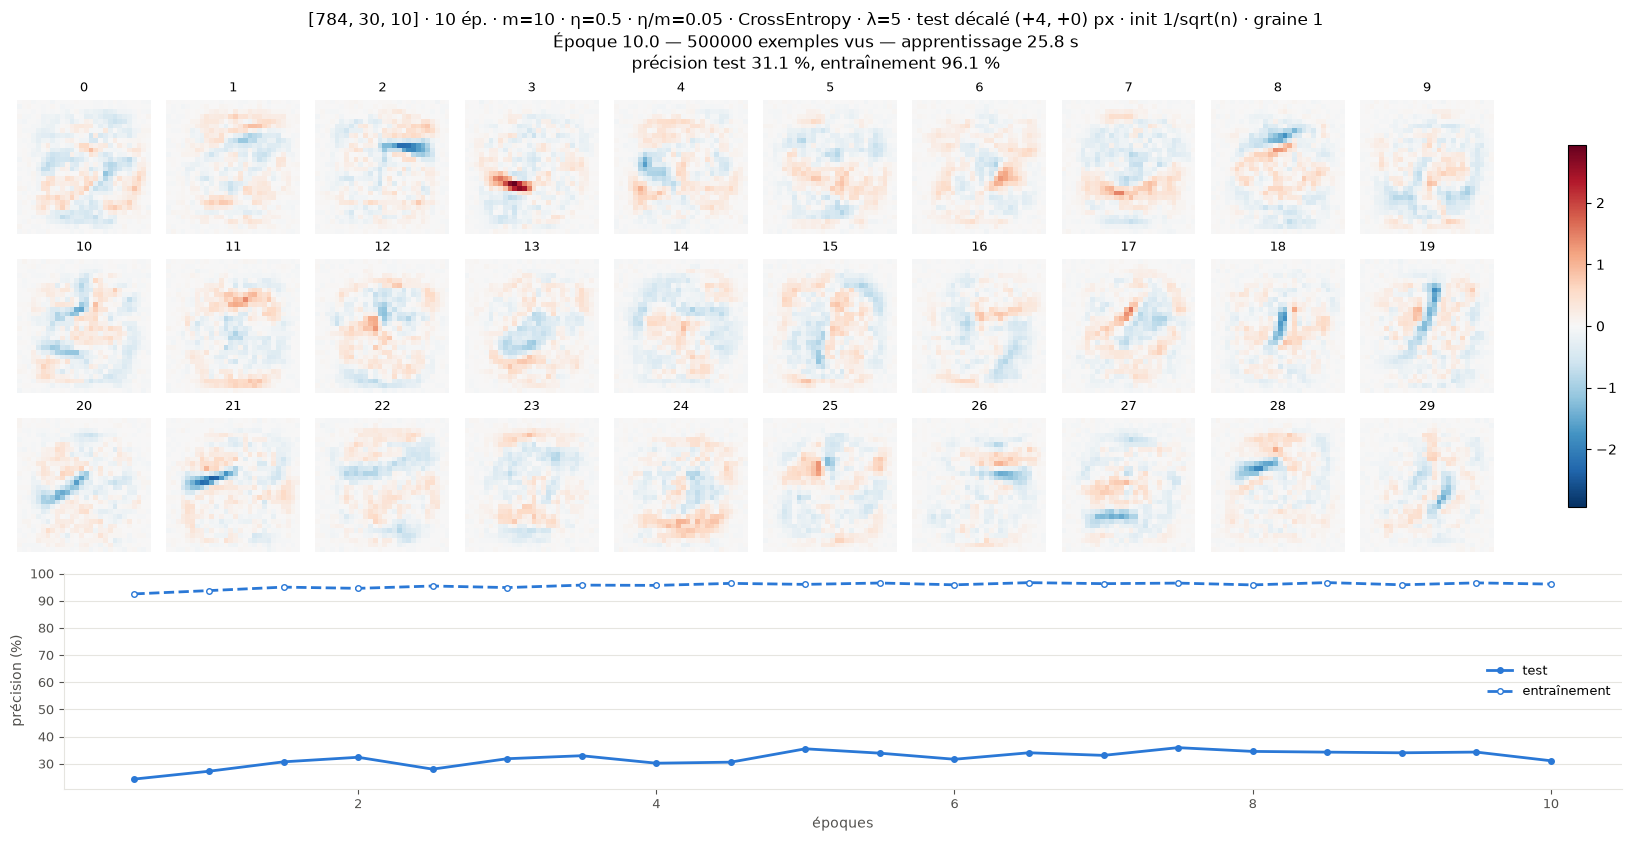

Temps d'apprentissage seul : 25.8 s   (mesure de la précision : 5.1 s, affichage : 19.4 s, total : 50.3 s)
Série « essais_invariances » enregistrée : 5 essais (resultats/essais_invariances.csv et .json)
Essai #5 : [784, 30, 10] · 10 ép. · m=10 · η=0.5 · η/m=0.05 · CrossEntropy · λ=5 · test décalé (+4, +0) px · init 1/sqrt(n) · graine 1


In [13]:
# 3. LANCER UN ESSAI
if SERIE != serie_chargee:                       # changement de série dans les paramètres
    essais, serie_chargee = charger_serie(SERIE), SERIE

if not CONTINUER or "net" not in globals():
    random.seed(GRAINE); np.random.seed(GRAINE)
    net = creer_reseau(ARCHITECTURE, RESEAU, COUT, INIT)
    W0 = net.weights[0].copy()                   # photo des poids avant entraînement

donnees, donnees_test, permutation = preparer_donnees(
    training_original, test_data, N_IMAGES, PERMUTER, DECALAGE_TEST)
historique = entrainer_en_direct(
    net, donnees, EPOQUES, TAILLE_BATCH, ETA, test_data=donnees_test,
    lmbda=LMBDA, images_par_epoque=IMAGES_PAR_EPOQUE,
    reference=W0 if VOIR_DIFFERENCE else None, echelle=ECHELLE,
    aussi_entrainement=AUSSI_ENTRAINEMENT,
    permutation=permutation if VOIR_ORDRE_ORIGINAL else None,
    etiquette=etiquette_essai(RESEAU, INIT, GRAINE, CONTINUER, NOTE, PERMUTER, DECALAGE_TEST))

essais.append(historique)
exporter(essais, SERIE)
print("Essai #%d : %s" % (len(essais), historique.nom))

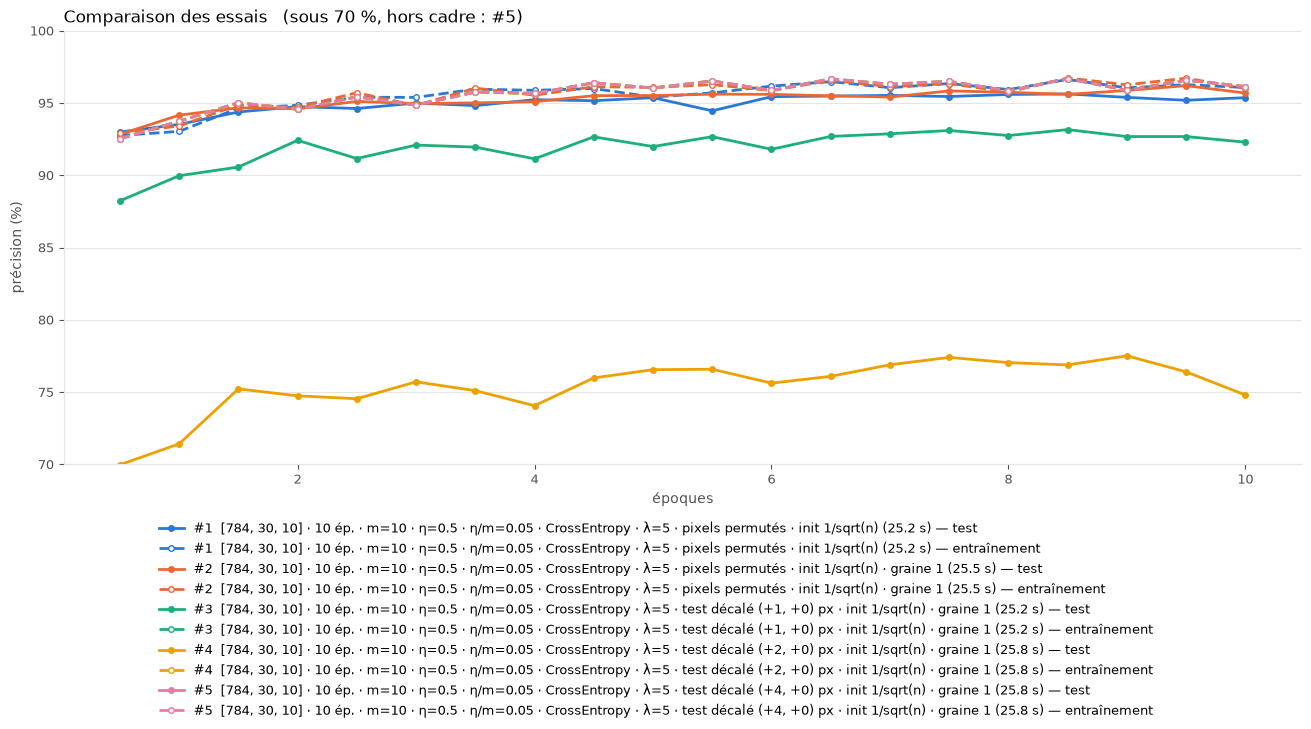

In [14]:
# 4. COMPARER
comparer(essais, filtre=FILTRE, ylim=YLIM)

In [ ]:
# 5. REGARDER LES POIDS DU RÉSEAU EN COURS (facultatif)
perm_affichage = permutation if VOIR_ORDRE_ORIGINAL else None
afficher_poids(net, titre="Poids actuels", echelle=ECHELLE, permutation=perm_affichage)
afficher_poids(net, reference=W0, titre="Ce que l'entraînement a changé", echelle=ECHELLE,
               permutation=perm_affichage)

In [ ]:
# 6. APERÇU DES TRANSFORMATIONS (facultatif) : une image de test décalée et permutée
apercu_transformations(test_data, index=0, decalages=(2, 4))

### Gérer la série
- Retirer l'essai n° k : `del essais[k-1]` puis `exporter(essais, SERIE, ecraser=True)`.
- Nouvelle série : change `SERIE` dans les paramètres ; elle est créée (ou rechargée) au prochain essai.
- Après chaque enregistrement, la version précédente est gardée dans `resultats/<SERIE>.precedent.json` / `.csv`.
- `exporter` refuse d'écrire si le fichier contient plus d'essais que la série en mémoire.